# 01 - Dataset Exploration

This notebook explores the CarePilot `ml_training.historical_tickets` dataset for the first AI benchmarking task: transfer prediction.

Target variable: `transfer_required`.

The goal is to verify dataset quality before model training: class balance, missingness, ticket text length, perimeter and priority distributions, and early correlations between operational signals and transfer.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "ml").exists():
    ROOT = next(parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "ml").exists())

BENCHMARK_DIR = ROOT / "ml" / "benchmarks" / "transfer"
if str(BENCHMARK_DIR) not in sys.path:
    sys.path.append(str(BENCHMARK_DIR))

PLOTS_DIR = ROOT / "ml" / "plots"
ARTIFACTS_DIR = ROOT / "ml" / "artifacts"
REPORTS_DIR = ROOT / "ml" / "reports"
for directory in [PLOTS_DIR, ARTIFACTS_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 140)

from preprocessing import load_database_url, load_transfer_dataset, load_ml_training_table_counts, prepare_dataframe

## Dataset Loading

The dataset is loaded from the isolated `ml_training` schema. No operational dashboard data or `cp_agent` AI metrics are modified.

In [2]:
database_url = load_database_url(ROOT)
raw_df = load_transfer_dataset(database_url)
table_counts = load_ml_training_table_counts(database_url)
df = prepare_dataframe(raw_df)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
display(raw_df.head(8))

dataset_overview = {
    "rows": int(len(df)),
    "historical_actions": table_counts["historical_actions"],
    "historical_resolutions": table_counts["historical_resolutions"],
    "km_articles": table_counts["km_articles"],
    "positive_transfer_rate": round(float(df["transfer_required"].mean()), 4),
    "unique_perimeters": int(df["perimeter"].nunique()),
    "unique_priorities": int(df["priority"].nunique()),
    "unique_incident_categories": int(df["incident_category"].nunique()),
}
dataset_overview

Rows: 14,000
Columns: 10


,ticket_id,title,description,perimeter,priority,sla_breached,resolution_time_minutes,incident_category,transfer_required
0,ML-CARE-000001,coupon engine timeout,coupon engine timeout - customer discount not ...,Loyalty,Medium,False,NaN,COUPON_VALIDATION_TIMEOUT,False
1,ML-CARE-000002,dns resolution failure failure at store,checkout subnet affected at Carrefour Market P...,LAN/WAN,Critical,True,797.0,DNS_RESOLUTION_FAILURE,True
2,ML-CARE-000003,POS lane down,POS lane down - cashier cannot process baskets...,Checkout (VLP),Low,False,1634.0,CHECKOUT_LANE_UNAVAILABLE,False
3,ML-CARE-000004,backup backup job failed - store systems,None,local server,High,False,NaN,BACKUP_JOB_FAILED,True
4,ML-CARE-000005,PIN pad encryption error,key mismatch; impact reported by store ops. Ne...,Payment,Medium,False,1767.0,PINPAD_ENCRYPTION_ERROR,False
5,ML-CARE-000006,Store server unreachable,Store server unreachable lanes in degraded mod...,Store Infrastructure,Low,False,1951.0,STORE_SERVER_UNREACHABLE,False
6,ML-CARE-000007,receipt printer offline,receipt printer offline. printer offline in PO...,Hardware,High,False,939.0,RECEIPT_PRINTER_OFFLINE,True
7,ML-CARE-000008,database volume critical,queries slowing. Vendor not yet contacted. Ple...,STORE INFRA,Medium,False,NaN,DISK_THRESHOLD_DATABASE,False


{'rows': 14000,
 'historical_actions': 34856,
 'historical_resolutions': 10356,
 'km_articles': 92,
 'positive_transfer_rate': 0.4,
 'unique_perimeters': 8,
 'unique_priorities': 4,
 'unique_incident_categories': 45}

## Missing Values and Text Length

This section checks whether the dataset contains controlled imperfections: missing descriptions, missing resolution time, and variable ticket text length.

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)

text_df = df.copy()
text_df["description_length"] = raw_df["description"].fillna("").astype(str).str.len()
text_df["title_length"] = raw_df["title"].fillna("").astype(str).str.len()
text_df["ticket_text_length"] = text_df["ticket_text"].str.len()

print("Missing values summary")
display(missing_summary)

print("Ticket text length summary")
display(text_df[["title_length", "description_length", "ticket_text_length"]].describe().round(2))

Missing values summary


,missing_count,missing_pct
resolution_time_minutes,3644,26.03
description,1134,8.10
ticket_id,0,0.00
perimeter,0,0.00
title,0,0.00
priority,0,0.00
sla_breached,0,0.00
incident_category,0,0.00
transfer_required,0,0.00


Ticket text length summary


,title_length,description_length,ticket_text_length
count,14000.00,14000.00,14000.00
mean,24.34,113.55,135.23
std,5.14,42.90,42.34
min,13.00,0.00,13.00
25%,21.00,103.00,122.75
50%,24.00,115.00,137.00
75%,27.00,128.00,152.00
max,42.00,275.00,295.00


## Distribution Analysis

The following plots validate that the dataset is benchmark-ready: balanced enough for learning, but not perfectly uniform or overly clean.

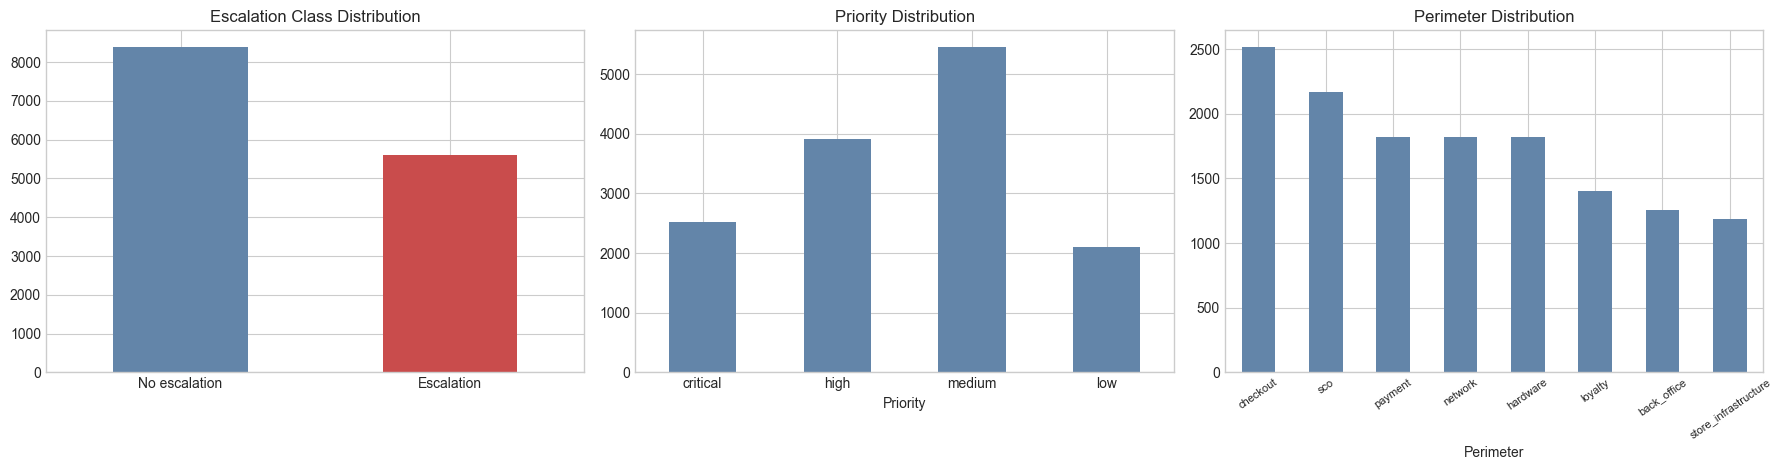

,class_pct
transfer_required,
0,60.0
1,40.0


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

class_counts = df["transfer_required"].map({0: "No transfer", 1: "transfer"}).value_counts()
class_counts.plot(kind="bar", ax=axes[0], color=["#6385a9", "#c94c4c"])
axes[0].set_title("transfer Class Distribution")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

priority_order = ["critical", "high", "medium", "low", "unknown"]
priority_counts = df["priority"].value_counts().reindex(priority_order).dropna()
priority_counts.plot(kind="bar", ax=axes[1], color="#6385a9")
axes[1].set_title("Priority Distribution")
axes[1].set_xlabel("Priority")
axes[1].tick_params(axis="x", rotation=0)

perimeter_counts = df["perimeter"].value_counts().sort_values(ascending=False)
perimeter_counts.plot(kind="bar", ax=axes[2], color="#6385a9")
axes[2].set_title("Perimeter Distribution")
axes[2].set_xlabel("Perimeter")
axes[2].tick_params(axis="x", rotation=35, labelsize=8)

fig.tight_layout()
fig.savefig(PLOTS_DIR / "01_distribution_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "class_pct": (df["transfer_required"].value_counts(normalize=True).sort_index() * 100).round(2),
}))

C:\Users\ar202\AppData\Local\Temp\ipykernel_19608\3503399392.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(boxplot_data, labels=["No transfer", "transfer"], patch_artist=True)


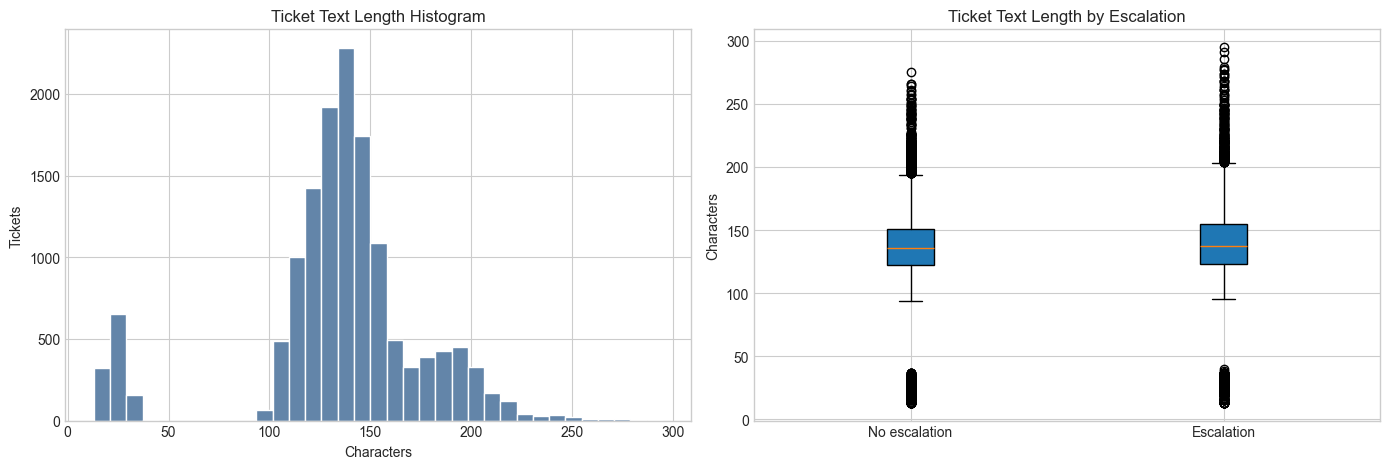

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].hist(text_df["ticket_text_length"], bins=35, color="#6385a9", edgecolor="white")
axes[0].set_title("Ticket Text Length Histogram")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Tickets")

boxplot_data = [
    text_df.loc[text_df["transfer_required"] == 0, "ticket_text_length"],
    text_df.loc[text_df["transfer_required"] == 1, "ticket_text_length"],
]
axes[1].boxplot(boxplot_data, labels=["No transfer", "transfer"], patch_artist=True)
axes[1].set_title("Ticket Text Length by transfer")
axes[1].set_ylabel("Characters")

fig.tight_layout()
fig.savefig(PLOTS_DIR / "01_ticket_length_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

## Correlation Exploration

This is an exploratory check, not a causal analysis. It helps identify whether operational fields carry useful signal without creating perfect separation.

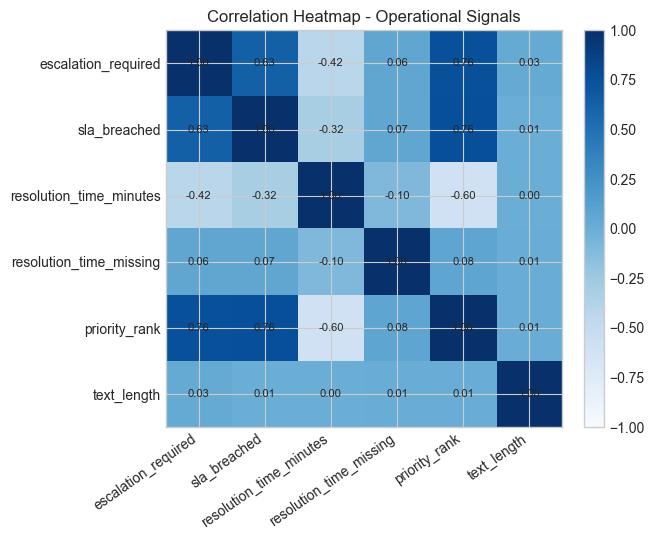

,transfer_required,sla_breached,resolution_time_minutes,resolution_time_missing,priority_rank,text_length
transfer_required,1.000,0.626,-0.424,0.064,0.757,0.033
sla_breached,0.626,1.000,-0.317,0.068,0.762,0.006
resolution_time_minutes,-0.424,-0.317,1.000,-0.097,-0.598,0.000
resolution_time_missing,0.064,0.068,-0.097,1.000,0.078,0.009
priority_rank,0.757,0.762,-0.598,0.078,1.000,0.014
text_length,0.033,0.006,0.000,0.009,0.014,1.000


In [8]:
analysis_df = df.copy()
analysis_df["resolution_time_missing"] = analysis_df["resolution_time_minutes"].isna().astype(int)
analysis_df["resolution_time_minutes"] = analysis_df["resolution_time_minutes"].fillna(analysis_df["resolution_time_minutes"].median())
analysis_df["priority_rank"] = analysis_df["priority"].map({"low": 1, "medium": 2, "high": 3, "critical": 4}).fillna(0)
analysis_df["text_length"] = text_df["ticket_text_length"]

corr_cols = ["transfer_required", "sla_breached", "resolution_time_minutes", "resolution_time_missing", "priority_rank", "text_length"]
corr = analysis_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=35, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation Heatmap - Operational Signals")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "01_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

display(corr.round(3))

In [9]:
imbalance_summary = {
    "transfer_positive_pct": round(float(df["transfer_required"].mean() * 100), 2),
    "largest_perimeter_pct": round(float(df["perimeter"].value_counts(normalize=True).max() * 100), 2),
    "largest_priority_pct": round(float(df["priority"].value_counts(normalize=True).max() * 100), 2),
    "avg_ticket_text_length": round(float(text_df["ticket_text_length"].mean()), 2),
}

(ARTIFACTS_DIR / "01_dataset_exploration_summary.json").write_text(json.dumps(imbalance_summary, indent=2), encoding="utf-8")
imbalance_summary

{'transfer_positive_pct': 40.0,
 'largest_perimeter_pct': 18.0,
 'largest_priority_pct': 39.0,
 'avg_ticket_text_length': 135.23}